YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed


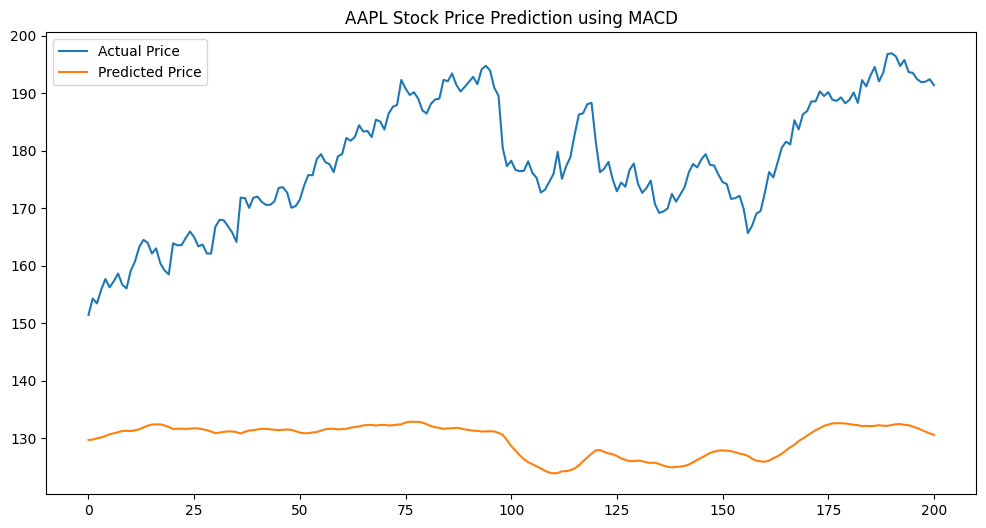

Model R^2 Score: -19.4616


In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Step 1: Download stock data
ticker = "AAPL"  # You can change this
data = yf.download(ticker, start="2020-01-01", end="2024-01-01")

# Step 2: Calculate MACD
# MACD = 12 EMA - 26 EMA
# Signal Line = 9 EMA of MACD
data['EMA12'] = data['Close'].ewm(span=12, adjust=False).mean()
data['EMA26'] = data['Close'].ewm(span=26, adjust=False).mean()
data['MACD'] = data['EMA12'] - data['EMA26']
data['Signal_Line'] = data['MACD'].ewm(span=9, adjust=False).mean()

# Step 3: Prepare data for modeling
# We'll use MACD and Signal Line to predict next day's closing price
data['Target'] = data['Close'].shift(-1)  # Predict next day's close

# Drop rows with NaN
data = data.dropna()

# Features and labels
X = data[['MACD', 'Signal_Line']]
y = data['Target']

# Step 4: Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Step 5: Train a model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = model.predict(X_test)

# Step 7: Plot actual vs predicted
plt.figure(figsize=(12,6))
plt.plot(y_test.values, label='Actual Price')
plt.plot(y_pred, label='Predicted Price')
plt.title(f"{ticker} Stock Price Prediction using MACD")
plt.legend()
plt.show()

# Step 8: Print score
score = model.score(X_test, y_test)
print(f"Model R^2 Score: {score:.4f}")
